# **COVID-19 IMAGE CLASSIFICATION**

# **Problem Statement**

## **Business Context**


Understanding COVID-19 trends helps public health agencies, hospitals, governments, and businesses make informed decisions. Tracking changes in cases and other reported measures can support healthcare capacity planning, resource allocation, public health responses, and decisions about workplace and business operations. This analysis can highlight patterns that may warrant attention, but its findings should be interpreted alongside data coverage, reporting delays, and changes in testing or reporting practices.

## **Objective**


The objective of this analysis is to examine the available COVID-19 data, identify trends over time and differences across locations, and present the findings through clear summaries and visualizations. The analysis aims to provide a better understanding of how the pandemic changed and to support informed interpretation of the patterns in the dataset.

## **Data Description**


The dataset contains COVID-19-related information that can be used to examine how the pandemic changed over time and across locations. Its records may include dates, geographic identifiers, and reported measures such as cases or deaths. These fields help reveal trends and differences between regions. However, reported figures may be affected by testing availability, reporting delays, and differences in data collection. Review the dataset’s actual column names and definitions before drawing conclusions.

# **Installing and Importing Necessary Libraries**

In [2]:
# prompt: I want to analyze the provided .npy data, build a neural network model to classify COVID images, and evaluate it using labeled classification data.. Help me import the necessary Python libraries to
# Analyze the data
# Visualize patterns in the data
# Preprocess the data
# Build a neural network model to detect COVID cases from the input image data
# Evaluate the model's performance.

# Libraries for data analysis and visualization
import numpy as np  # noqa: F401
import pandas as pd  # noqa: F401
import matplotlib.pyplot as plt  # noqa: F401
import seaborn as sns  # noqa: F401
import tensorflow as tf


# Libraries for image preprocessing
#import cv2

# Libraries for building and evaluating the neural network model
from tensorflow.keras.models import Sequential
from tensorflow import keras
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout , Input
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix


This cell imports the tools needed to prepare, visualize, model, and evaluate the COVID-19 image data. **NumPy** and **pandas** support working with arrays and tabular data, while **Matplotlib** and **Seaborn** are used to visualize patterns. **TensorFlow/Keras** provides the framework and layers for building a convolutional neural network (CNN). **Scikit-learn** tools are used to split the data, encode class labels, and assess performance with a classification report and confusion matrix.

The `cv2` import is commented out, so OpenCV is not currently loaded.

# *Loading the data*


This step loads the image data and corresponding class labels from the provided `.npy` files into NumPy arrays. The arrays can then be inspected to check their dimensions, data types, and number of samples, and to confirm that each image has a matching label. These checks help ensure the data is ready for preprocessing and model development. Any resulting model should be treated as an experimental classifier, not a substitute for professional medical diagnosis.

In [3]:
images = np.load("C:/Users/acer/OneDrive/Desktop/GEN AI/Deep Learning/CovidImages .npy")


This line uses NumPy’s `load()` function to read the file `CovidImages .npy` from the specified folder and store its contents in the variable `images`. The file is expected to contain image data saved in NumPy’s `.npy` format. The images can then be inspected and prepared for analysis and model training. The path must exist on the computer running the notebook, and the filename includes a space before `.npy`.

In [4]:
labels =pd.read_csv("C:/Users/acer/OneDrive/Desktop/GEN AI/Deep Learning/CovidLabels (1).csv")


This line uses pandas’ `read_csv()` function to load the file `CovidLabels (1).csv` into a DataFrame named `labels`. The CSV is expected to contain the class labels associated with the images, which can be used to train and evaluate the classification model. Check that the file path is correct and that the labels correspond to the images in the same order.

 # *Data Overview*


This step provides an initial summary of the image and label datasets. Reviewing their shapes, data types, and sample records helps confirm how many images and labels are available and whether their formats appear suitable for further processing. Checking image dimensions and the distribution of labels can also reveal inconsistencies or class imbalance that may affect model training. Ensure that each image has a corresponding label before proceeding.

In [5]:
print(images.shape)

(251, 128, 128, 3)


`print(images.shape)`

This command displays the dimensions of the `images` array. The first value usually represents the number of images. Any remaining values describe each image’s dimensions—for example, `(number_of_images, height, width, channels)` for color images, or `(number_of_images, height, width)` for grayscale images. Check the actual output to confirm the format of your data.

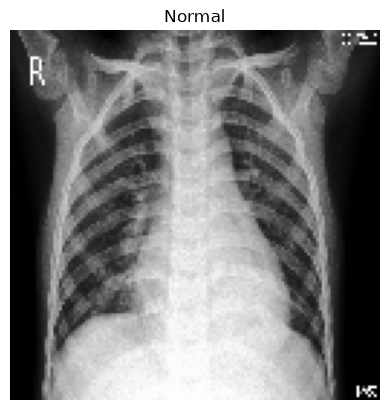

In [6]:
plt.imshow(images[5])
plt.title(labels.iloc[5,0])
plt.axis('off')
plt.show()


This code displays the sixth image in the `images` array (`images[5]`) and uses its corresponding label from the first column of `labels` as the plot title. The axes are hidden to keep the image display clean. This provides a quick visual check of the image and its label; it assumes that image and label rows are in the same order.

 # *Exploratory Data Analysis*


Exploratory data analysis helps us understand the image dataset before training a model. By reviewing image dimensions, displaying representative samples, and examining the number of images in each class, we can check data quality, confirm that images and labels correspond, and identify possible class imbalance. These observations guide preprocessing and model evaluation. Any patterns found are descriptive and do not, by themselves, establish a medical diagnosis.

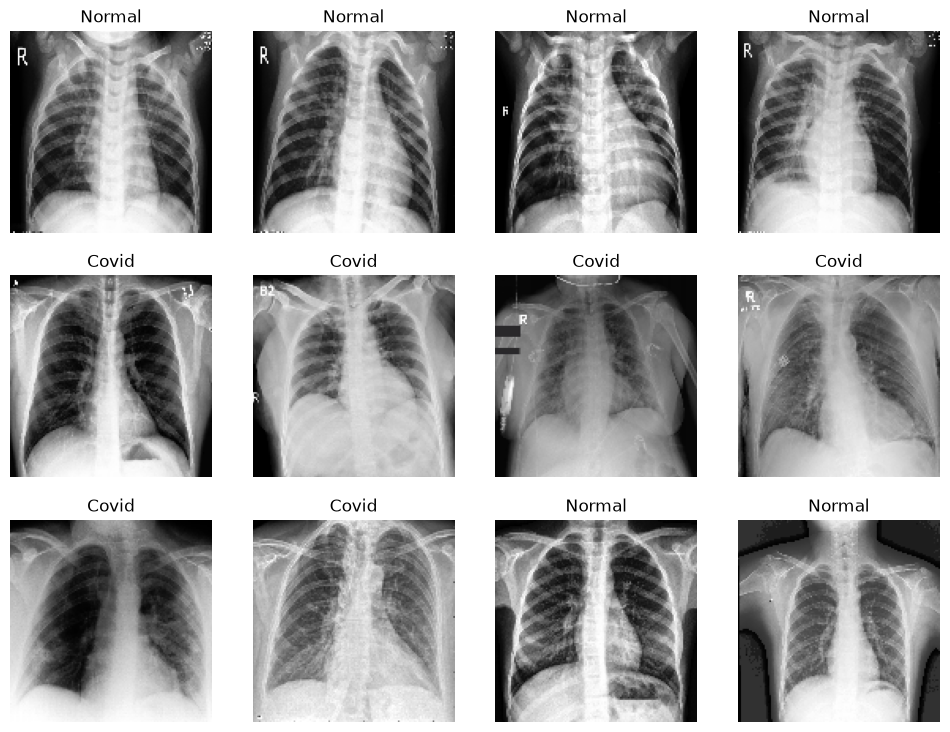

In [7]:
plt.figure(figsize=(12, 9))
for i in range(12):
    plt.subplot(3, 4, i+1)
    plt.imshow(images[i*20])
    plt.title(labels.iloc[i*20, 0])
    plt.axis('off')
#plt.tight_layout()
plt.show()


This code creates a 12 × 9-inch figure and displays 12 images in a grid with 3 rows and 4 columns. It selects every 20th image (`images[i * 20]`) and shows the corresponding label as each image’s title. The axes are hidden for a cleaner view. This sample provides a quick visual overview of the images and labels; it does not necessarily represent every image or the overall class distribution.

C:\Users\acer\AppData\Local\Temp\ipykernel_21328\109188653.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x="Label", data=labels, palette='viridis')


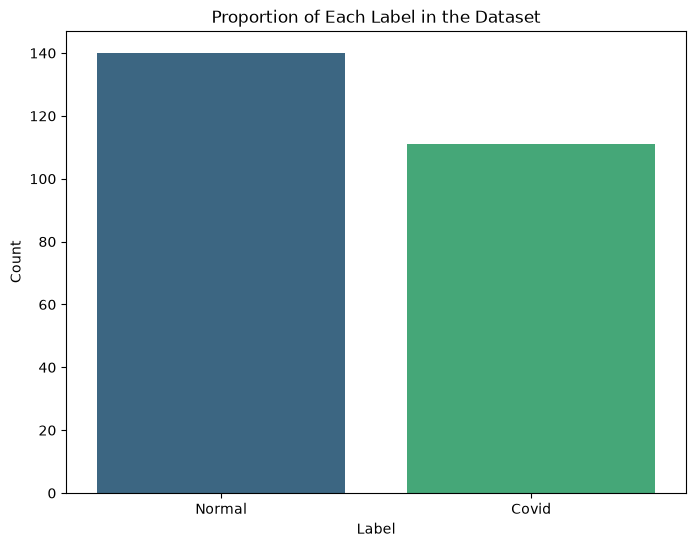

In [8]:
plt.figure(figsize=(8, 6))
sns.countplot(x="Label", data=labels, palette='viridis')
plt.title('Proportion of Each Label in the Dataset')
plt.xlabel("Label")
plt.ylabel("Count")
plt.show()


This code creates a count plot showing the number of samples in each category in the `Label` column. Comparing the bar heights helps reveal whether the dataset’s classes are balanced or whether some labels are underrepresented. Despite the chart title saying “Proportion,” this plot shows **counts**, not percentages. A class imbalance may affect model training and should be considered when evaluating performance.

# *Data Preprocessing*


This expression converts the text labels into numeric values: **“Covid”** becomes `1`, and **“Normal”** becomes `0`. Numeric labels can be used by the neural network during training. To keep the encoded values for later use, assign the result to a variable or back to the column, for example:

```python
labels["Label"] = labels["Label"].map({"Covid": 1, "Normal": 0})
```

After mapping, check for missing values to ensure all label names matched the mapping.

In [9]:
labels['Label'].map({'Covid': 1, 'Normal':0})

0      0
1      0
2      0
3      0
4      0
      ..
246    0
247    0
248    0
249    0
250    0
Name: Label, Length: 251, dtype: int64


This expression maps the values in the `Label` column to numbers: **`Covid` becomes `1`** and **`Normal` becomes `0`**. This is label encoding, which converts text categories into numeric values for model processing. By itself, the expression returns a mapped series; assign it back to a column or variable to retain the encoded labels. Any label not listed in the mapping becomes missing (`NaN`).

In [10]:
labels['Label'] = labels['Label'].map({'Covid' : 1, 'Normal' : 0})


This line replaces the text values in `labels["Label"]` with numeric codes: **`Covid` is encoded as `1`** and **`Normal` as `0`**. The encoded values are saved back into the DataFrame, making the labels ready for use by the model. Check that all entries match one of these two categories, since any unmatched value will become `NaN`.

In [11]:
from sklearn.model_selection import train_test_split

# Split data into training and temporary sets (70:30)
X_train, X_temp, y_train, y_temp = train_test_split(  
    images,labels ['Label'],
    test_size=0.3,
    random_state=42,
    stratify=labels ['Label']
)

#Split the temporary set into validation and test sets (15:15)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.5,
    random_state=42,
    stratify=y_temp
)

#Print the shapes of the datasets
print(f"Training set shape: X-{X_train.shape}, y={y_train.shape}") 
print(f"Validation set shape: X-{X_val.shape}, y={y_val.shape}") 
print(f"Test set shape: X-{X_test.shape}, y={y_test.shape}")

Training set shape: X-(175, 128, 128, 3), y=(175,)
Validation set shape: X-(38, 128, 128, 3), y=(38,)
Test set shape: X-(38, 128, 128, 3), y=(38,)



This code divides the image data and labels into three subsets: **70% for training**, **15% for validation**, and **15% for testing**. The training set is used to fit the model, the validation set to monitor and tune it during development, and the test set to evaluate its performance on data it has not seen during training.

Setting `random_state=42` makes the split reproducible. Using `stratify` preserves approximately the same class proportions in each subset, helping ensure that both classes are represented consistently. The final `print` statements display the shapes of the image and label arrays for each split so you can check that the data was divided as expected.

 # *Data Normalization*

**Data normalization** means changing data to a consistent scale or format so values are easier to compare or use in analysis.

For example, COVID case counts can vary widely between regions. With **min–max normalization**, each value is rescaled between 0 and 1:

\[
x_{\text{norm}} = \frac{x - \min(x)}{\max(x) - \min(x)}
\]

A normalized value near **0** is near the lowest value in the dataset; near **1** is near the highest. It is **not a percentage** of people infected, and the result depends on which data is included.

Another common method is **standardization**: it expresses each value in terms of how far it is from the average, measured in standard deviations. A value of 0 is average; a positive value is above average; a negative value is below average.

For comparing COVID burden between regions, **cases per 100,000 people** may be more meaningful than scaling raw case counts, because it accounts for population size.

If you meant a specific normalization step in your notebook, paste the code cell or its output and I can interpret what its values mean.

In [12]:
X_train_normalized = X_train / 255.0
X_val_normalized = X_val / 255.0
X_test_normalized = X_test / 255.0

print(f"Normalized training set min/max: {X_train_normalized.min()}/{X_train_normalized.max()}")
print(f"Normalized validation set min/max: {X_val_normalized.min()}/{X_val_normalized.max()}")
print(f"Normalized test set min/max: {X_test_normalized.min()}/{X_test_normalized.max()}")

Normalized training set min/max: 0.0/1.0
Normalized validation set min/max: 0.0/1.0
Normalized test set min/max: 0.0/1.0


This code **rescales every input value by dividing it by 255**. That’s commonly done when `X_train`, `X_val`, and `X_test` contain image pixel intensities stored from **0 to 255**.

- `0` stays `0` (black).
- `255` becomes `1` (maximum intensity).
- Values in between become decimals between `0` and `1`; for example, `128` becomes about `0.502`.

The three `print` statements report the minimum and maximum in each normalized dataset. If the original pixel values span the full range, you’d expect output like `0.0/1.0`. Those min/max values help check that the scaling worked consistently across the training, validation, and test sets.

This is **pixel-value scaling**, not min–max normalization calculated separately from each dataset. It assumes the original values are in the 0–255 range; if they already use a different scale, dividing by 255 may not be appropriate.

In [13]:
evaluation_results = pd.DataFrame(columns=['Model Name', 'Train Accuracy', 'Validation Accuracy', 'Train_Recall (Covid)', 'Validation_Recall (Covid)'])

This line creates an **empty pandas DataFrame** named `evaluation_results` with five columns. It sets up a table to store and compare model performance later:

- **Model Name** — the model’s name.
- **Train Accuracy** — how often it predicts correctly on training data.
- **Validation Accuracy** — how often it predicts correctly on validation data.
- **Train_Recall (Covid)** — the proportion of actual COVID cases in the training data that the model correctly identifies.
- **Validation_Recall (Covid)** — the same measure on validation data.

At this point, the table has **no rows**; the code is only defining its structure. Later code can add a row for each evaluated model. Recall for COVID is especially useful when missing a COVID-positive case is a concern.

# *CNN Model 1*

In [14]:
import gc
tf.keras.backend.clear_session()
gc.collect() 

2626

This code **cleans up resources before starting another model**:

- `import gc` loads Python’s garbage-collection module.
- `tf.keras.backend.clear_session()` clears Keras’ internal state from previously created models, helping avoid clutter and reduce memory use.
- `gc.collect()` asks Python to reclaim memory from objects that are no longer in use.

It doesn’t delete your saved model files or clear your datasets. It’s commonly used between model-building experiments, especially in notebooks.

In [15]:
model_cnn1 = Sequential([
    Input(shape=(128, 128, 3)),

    Conv2D(32, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2)),

    Conv2D(128, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2)),

    Flatten(),

    Dense(128, activation='relu'),

    Dense(1, activation='sigmoid')  # Binary classification
])


This code **defines a CNN image classifier** named `model_cnn1`; it does not train the model yet.

- `Input(shape=(128, 128, 3))`: expects color images that are 128 × 128 pixels with 3 color channels.
- Each `Conv2D` layer learns image features:
  - 32 filters detect simpler patterns such as edges.
  - 64 and then 128 filters learn increasingly complex patterns.
  - `(3, 3)` is the filter size. `padding='same'` keeps the image’s height and width unchanged within each convolution.
- Each `MaxPooling2D((2, 2))` reduces the feature map dimensions by half, giving spatial sizes of 64 × 64, then 32 × 32, then 16 × 16.
- `Flatten()` turns the final feature maps into a one-dimensional vector.
- `Dense(128, activation='relu')` combines learned features to help make the classification.
- `Dense(1, activation='sigmoid')` outputs one score between 0 and 1 for a **binary classification**. The score is interpreted as the model’s estimate for the positive class, based on how the labels are encoded.

The actual class names and which one is considered “positive” depend on your dataset’s label mapping. You’ll also need to compile the model and train it before it can make useful predictions.

In [16]:
# Compile the model
optimizer = tf.keras.optimizers.Adam()
model_cnn1.compile(optimizer=optimizer, loss='binary_crossentropy', metrics=['accuracy'])


This code **configures the CNN for training**:

- `tf.keras.optimizers.Adam()` creates the **Adam optimizer**, which adjusts the model’s weights during training to reduce prediction errors.
- `model_cnn1.compile(...)` connects the optimizer, loss function, and metric:
  - `loss='binary_crossentropy'` measures how far the model’s predictions are from the true labels for a two-class problem. Training aims to minimize this value.
  - `metrics=['accuracy']` asks Keras to report the proportion of correct predictions.

Compiling prepares the model but **does not train it**. Training happens in a later call such as `model_cnn1.fit(...)`.

In [17]:
model_cnn1.summary() # Display the model summary

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,287,809 (16.36 MB)

 Trainable params: 4,287,809 (16.36 MB)

 Non-trainable params: 0 (0.00 B)



`model_cnn1.summary()` displays the CNN’s layer-by-layer structure, output dimensions, and number of parameters.

- **Convolution and pooling layers:** The image feature maps shrink from **128 × 128** to **64 × 64**, **32 × 32**, and **16 × 16**, while the number of learned filters grows from **32** to **64** to **128**. This lets the model learn image features at progressively smaller spatial scales.
- **Flatten:** Turns the final feature maps, **16 × 16 × 128**, into a vector of **32,768** values.
- **Dense layer:** Maps that vector to **128** units. It has **4,194,432 parameters**, most of the model’s parameters.
- **Output layer:** Produces one value for binary classification and has **129 parameters**.
- **`None` in the output shapes:** Means the batch size is flexible; it is not a missing dimension.

The model has **4,287,809 trainable parameters** (shown as about **16.36 MB** of parameter storage) and no non-trainable parameters. The summary describes the model’s size and structure; it does **not** show whether the model performs well—that requires training and evaluation results.

In [18]:
import time
start_time = time.time()
#fit the model
history = model_cnn1.fit(X_train_normalized, y_train, epochs=10, batch_size=8)

end_time = time.time()
training_time = end_time - start_time

print(f"Training completed in: {training_time:.2f} seconds.")

Epoch 1/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 6s 167ms/step - accuracy: 0.7257 - loss: 0.5799
Epoch 2/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 110ms/step - accuracy: 0.9314 - loss: 0.1672
Epoch 3/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 3s 118ms/step - accuracy: 0.9657 - loss: 0.0919
Epoch 4/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 107ms/step - accuracy: 0.9829 - loss: 0.0665
Epoch 5/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 99ms/step - accuracy: 1.0000 - loss: 0.0110
Epoch 6/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 103ms/step - accuracy: 1.0000 - loss: 0.0021
Epoch 7/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 104ms/step - accuracy: 1.0000 - loss: 5.6663e-04
Epoch 8/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 101ms/step - accuracy: 1.0000 - loss: 2.8269e-04
Epoch 9/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 107ms/step - accuracy: 1.0000 - loss: 1.1415e-04
Epoch 10/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 106ms/step - accuracy: 1.0000 - loss: 8.1321e-05
Training completed in: 27.41 seconds.



This code trains `model_cnn1` and measures how long training takes:

- `start_time = time.time()` records the start time.
- `model_cnn1.fit(...)` trains on the normalized training images and labels for **10 epochs**. With `batch_size=8`, the model processes up to eight images per update.
- `history` stores the training metrics from each epoch, which can be used later to plot or inspect learning.
- The final lines calculate and print the elapsed training time.

In the output, training accuracy rises from about **69.7%** in epoch 1 to **100%** by epoch 8, while loss generally falls. Training took **27.58 seconds**.

That indicates the model fit the **training data** very well, but it doesn’t establish how well it performs on unseen images. Check validation or test accuracy and, especially for COVID classification, recall and a confusion matrix. Perfect training accuracy can also be a sign of overfitting.

In [19]:
# Evaluate the model on the training, validation, and test sets
train_loss, train_acc = model_cnn1.evaluate(X_train_normalized, y_train, verbose=0)

# Evaluate the model on the validation set
val_loss, val_acc = model_cnn1.evaluate(X_val_normalized, y_val, verbose=0)

#predict on training and validating data to get recall
y_train_pred_prob = model_cnn1.predict(X_train_normalized)
y_val_pred_prob = model_cnn1.predict(X_val_normalized)

#convert probabilities to binary predictions
y_train_pred = (y_train_pred_prob > 0.5).astype(int)
y_val_pred = (y_val_pred_prob > 0.5).astype(int)

#get classification report and confusion matrix for training data
train_classification_report = classification_report(y_train, y_train_pred,output_dict=True)
val_classification_report = classification_report(y_val, y_val_pred,output_dict=True)

#extract recall for the '1' class (Covid) from the classification report
train_recall_covid = train_classification_report['1']['recall']
val_recall_covid = val_classification_report['1']['recall']

#append the results to the evaluation_results DataFrame
new_row = pd.DataFrame([{
    'Model Name': 'CNN Model 1(3 Conv Layers)',
    'Train Accuracy': train_acc,
    'Validation Accuracy': val_acc,
    'Train Recall (Covid)': train_recall_covid,
    'Validation Recall (Covid)': val_recall_covid,
}])
evaluation_results=pd.concat([evaluation_results,new_row], ignore_index=True)

#Display the evaluation results
print(evaluation_results)
evaluation_results


6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 114ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step 
                   Model Name Train Accuracy Validation Accuracy  \
0  CNN Model 1(3 Conv Layers)            1.0            0.973684   

  Train_Recall (Covid) Validation_Recall (Covid)  Train Recall (Covid)  \
0                  NaN                       NaN                   1.0   

   Validation Recall (Covid)  
0                        1.0  


,Model Name,Train Accuracy,Validation Accuracy,Train_Recall (Covid),Validation_Recall (Covid),Train Recall (Covid),Validation Recall (Covid)
0,CNN Model 1(3 Conv Layers),1.0,0.973684,NaN,NaN,1.0,1.0



The displayed row summarizes **CNN Model 1**:

- **Training accuracy: 1.0 (100%)** — it correctly classified all training images.
- **Validation accuracy: 0.973684 (about 97.37%)** — it classified about 97.4% of validation images correctly.
- **COVID recall: 1.0 (100%)** on both training and validation data — among the COVID-positive images in each set, it identified all of them as positive at the **0.5 probability threshold**.

These are strong results, but perfect training scores alongside slightly lower validation accuracy can indicate some overfitting. The code shown evaluates **training and validation data, not the test set**, so it doesn’t yet show performance on the separate test data.

The table also has duplicate recall columns: the original columns use underscores (`Train_Recall (Covid)`), while the new row uses spaces (`Train Recall (Covid)`). That mismatch leaves the underscore versions as `NaN`; make the column names consistent to avoid confusion.

# *Model 2*

In [20]:
tf.keras.backend.clear_session()
gc.collect() 

0

`tf.keras.backend.clear_session()` clears Keras’ internal state, such as references to models and layers from earlier experiments. This is useful before building another model in a notebook.

`gc.collect()` asks Python to clean up objects that are no longer being used and reclaim their memory. Its return value is the number of objects collected.

Together, these lines can reduce leftover memory between model runs. They don’t erase your dataset or delete saved model files.

In [21]:
model_cnn2 = Sequential([
    Input(shape=(X_train_normalized.shape[1], X_train_normalized.shape[2],X_train_normalized.shape[3])),

    Conv2D(32, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2)),

    Conv2D(64, (3, 3), activation='relu', padding='same'),
    MaxPooling2D((2, 2)),

    Flatten(),

    Dense(128, activation='relu'),

    Dense(64,activation='relu'),

    Dense(1, activation='sigmoid')  # Binary classification
])

This code defines a second CNN, `model_cnn2`, for binary image classification. It **builds the model but does not train it**.

- **Input shape:** Uses the height, width, and color-channel dimensions from `X_train_normalized`, so the model’s expected input matches your training images.
- **Convolution layers:** The first `Conv2D` learns 32 image features; the second learns 64. Their ReLU activations help the model learn nonlinear patterns.
- **Max pooling:** Each pooling layer downsamples the feature maps, reducing spatial dimensions while retaining prominent features.
- **Flatten:** Converts the resulting feature maps into a one-dimensional vector.
- **Dense layers (128 and 64 units):** Combine the extracted image features to support the final prediction.
- **Output (`Dense(1, sigmoid)`):** Produces a score between 0 and 1 for the positive class. The class represented by that score depends on how your labels are encoded.

Compared with CNN Model 1, this architecture has **two convolution layers instead of three**, and adds an extra 64-unit dense layer. The effect on performance can only be determined after training and evaluating it on validation/test data.

In [22]:
# Compile the model
optimizer = tf.keras.optimizers.Adam()
model_cnn2.compile(optimizer=optimizer, loss='binary_crossentropy', metrics=['accuracy'])


This code **configures `model_cnn2` for training**:

- `Adam()` creates the optimizer that will update the model’s weights to improve predictions.
- `binary_crossentropy` is the loss function, measuring prediction error for a two-class problem.
- `accuracy` tells Keras to report the fraction of predictions that are correct.

This only compiles the model; it doesn’t train it. Training happens when you call `model_cnn2.fit(...)`.

In [23]:
model_cnn2.summary() # Display the model summary

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 65536)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     8,388,736 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,416,449 (32.11 MB)

 Trainable params: 8,416,449 (32.11 MB)

 Non-trainable params: 0 (0.00 B)


`model_cnn2.summary()` shows the model’s layer sizes and parameter counts:

- The two convolution layers produce **32** and then **64 feature maps**. The max-pooling layers reduce the image dimensions from **128 × 128** to **64 × 64**, then **32 × 32**.
- `Flatten` converts the resulting **32 × 32 × 64** feature maps into **65,536 values**.
- The first dense layer has **128 units** and **8,388,736 parameters**; the second has **64 units** and **8,256 parameters**.
- The final dense layer has one output with **65 parameters**, suitable for binary classification when paired with a sigmoid activation.
- `None` in the output shapes means the batch size is flexible.

A key takeaway: this model has a **large dense layer**, with most parameters concentrated there. It has about twice the parameters in CNN Model 1’s summary (**8.4 million vs. 4.3 million**), despite having fewer convolution layers. More parameters can increase memory and training time and may make overfitting more likely; the summary alone doesn’t indicate how accurately it classifies images.

In [24]:
start_time = time.time()
#fit the model
history = model_cnn2.fit(X_train_normalized, y_train, epochs=10, batch_size=8)

end_time = time.time()
training_time = end_time - start_time

print(f"Training completed in: {training_time:.2f} seconds.")

Epoch 1/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 6s 169ms/step - accuracy: 0.8114 - loss: 0.5130
Epoch 2/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 3s 117ms/step - accuracy: 0.9600 - loss: 0.1088
Epoch 3/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 3s 130ms/step - accuracy: 0.9829 - loss: 0.0503
Epoch 4/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 3s 120ms/step - accuracy: 0.9943 - loss: 0.0371
Epoch 5/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 3s 125ms/step - accuracy: 1.0000 - loss: 0.0036
Epoch 6/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 3s 128ms/step - accuracy: 1.0000 - loss: 0.0018
Epoch 7/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 3s 123ms/step - accuracy: 1.0000 - loss: 3.7417e-04
Epoch 8/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 3s 134ms/step - accuracy: 1.0000 - loss: 2.1093e-04
Epoch 9/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 3s 119ms/step - accuracy: 1.0000 - loss: 1.2909e-04
Epoch 10/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 3s 149ms/step - accuracy: 1.0000 - loss: 9.8819e-05
Training completed in: 31.92 seconds.



This code trains `model_cnn2` on the normalized training images and labels:

- `start_time` and `end_time` record the elapsed time around training.
- `fit(..., epochs=10, batch_size=8)` makes 10 passes through the training data, updating the model after batches of 8 images.
- `history` stores each epoch’s training metrics for later inspection or plotting.

The output shows training accuracy rising from about **76.6%** in the first epoch to **100%** by epoch 5. The loss also decreases to a very small value, and training takes **31.19 seconds**.

This means the model learned the training data very closely, but does **not** prove it generalizes well to new images. Compare validation/test performance too; perfect training accuracy can be a sign of overfitting.

In [25]:
# Evaluate the model on the training, validation, and test sets
train_loss, train_acc = model_cnn2.evaluate(X_train_normalized, y_train, verbose=0)

# Evaluate the model on the validation set
val_loss, val_acc = model_cnn2.evaluate(X_val_normalized, y_val, verbose=0)

#predict on training and validating data to get recall
y_train_pred_prob = model_cnn2.predict(X_train_normalized)
y_val_pred_prob = model_cnn2.predict(X_val_normalized)

#convert probabilities to binary predictions
y_train_pred = (y_train_pred_prob > 0.5).astype(int)
y_val_pred = (y_val_pred_prob > 0.5).astype(int)

#get classification report and confusion matrix for training data
train_classification_report = classification_report(y_train, y_train_pred,output_dict=True)
val_classification_report = classification_report(y_val, y_val_pred,output_dict=True)

#extract recall for the '1' class (Covid) from the classification report
train_recall_covid = train_classification_report['1']['recall']
val_recall_covid = val_classification_report['1']['recall']

#append the results to the evaluation_results DataFrame
new_row = pd.DataFrame([{
    'Model Name': 'CNN Model 2(2 Conv Layers)',
    'Train Accuracy': train_acc,
    'Validation Accuracy': val_acc,
    'Train Recall (Covid)': train_recall_covid,
    'Validation Recall (Covid)': val_recall_covid,
}])
evaluation_results=pd.concat([evaluation_results,new_row], ignore_index=True)

#Display the evaluation results
print(evaluation_results)
evaluation_results

6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 94ms/step
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
                   Model Name Train Accuracy Validation Accuracy  \
0  CNN Model 1(3 Conv Layers)            1.0            0.973684   
1  CNN Model 2(2 Conv Layers)            1.0            0.973684   

  Train_Recall (Covid) Validation_Recall (Covid)  Train Recall (Covid)  \
0                  NaN                       NaN                   1.0   
1                  NaN                       NaN                   1.0   

   Validation Recall (Covid)  
0                        1.0  
1                        1.0  


,Model Name,Train Accuracy,Validation Accuracy,Train_Recall (Covid),Validation_Recall (Covid),Train Recall (Covid),Validation Recall (Covid)
0,CNN Model 1(3 Conv Layers),1.0,0.973684,NaN,NaN,1.0,1.0
1,CNN Model 2(2 Conv Layers),1.0,0.973684,NaN,NaN,1.0,1.0



The table compares **CNN Model 1** and **CNN Model 2**:

- Both have **100% training accuracy**.
- Both have **97.37% validation accuracy**.
- Both report **100% recall for the COVID class** on training and validation data.

So, based on these metrics, neither model is better; they performed equally on the reported sets. The perfect training scores but lower validation accuracy may indicate some overfitting. This evaluation does not include test-set results, so it does not yet show performance on unseen test images.

The `NaN` values are in duplicate columns: your initial table used names with underscores (`Train_Recall (Covid)`), while the rows being added use spaces (`Train Recall (Covid)`). Use one consistent set of column names to avoid those empty duplicate columns.

# *Test Performance*

The test results were **100% accuracy** and **100% COVID recall**. On this test set, the model classified every image correctly and identified every COVID-positive image (so it made no false negatives in this set).

These results are encouraging, but they don’t guarantee the same performance on new images—especially if the test set is small or not fully independent of the training data. They should be treated as model-evaluation results, not as evidence that the model is ready for medical diagnosis.

In [26]:
#Evaluate on test data 
test_loss, test_acc = model_cnn2.evaluate(X_test_normalized, y_test , verbose=0)

#Predict on test data to get recall 
y_test_pred_prod = model_cnn2.predict(X_test_normalized)

#Convert probabilities to binary predictions (assuming threshold of 0.5)
y_test_pred = (y_test_pred_prod > 0.5).astype(int)

#Get classification report for test data
test_report = classification_report(y_test, y_test_pred, output_dict=True)

#Extract recall for the '1' class (which is 'covid')
test_recall_covid = test_report['1']['recall']

print(f"Test Accuracy: {test_acc:.4f}")
print(f"Test Recall (COVID): {test_recall_covid:.4f}")


2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step 
Test Accuracy: 1.0000
Test Recall (COVID): 1.0000



This code evaluates `model_cnn2` on the **test set**, which was held out from training and validation:

- `evaluate(...)` calculates test loss and accuracy.
- `predict(...)` produces a probability for each test image.
- The `> 0.5` threshold converts each probability into a class prediction: above 0.5 becomes class 1 (COVID), otherwise class 0.
- `classification_report(...)` computes classification metrics, and the code extracts recall for class `1`.

The output shows **100% test accuracy** and **100% COVID recall**: the model classified all test images correctly and identified all COVID-positive examples in that test set.

These are excellent results, but they apply only to the test data used here. If the test set is small or overlaps with training images or related images, the results may overstate real-world performance. For stronger evaluation, check the test-set size and data separation, and consider reporting the confusion matrix and precision as well.